In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Setting style
sns.set_theme(style="whitegrid")

# LOADING AMAZON DATSET

df_raw = pd.read_csv(r"C:\Users\User\Desktop\bestsellers_with_categories_2022_03_27.csv")

print(f"Successfully loaded file with {len(df_raw)} entries.")

Successfully loaded file with 700 entries.


In [4]:
# EXPLORATORY DATA ANALYSIS (EDA)

print("\n--- A. EXPLORATORY DATA ANALYSIS (EDA) ---")

# 1. Structure of the Data
print("\n[EDA Step 1] Dataset Shape:", df_raw.shape)
print("\n[EDA Step 1] Dataset Info:")
df_raw.info()


--- A. EXPLORATORY DATA ANALYSIS (EDA) ---

[EDA Step 1] Dataset Shape: (700, 7)

[EDA Step 1] Dataset Info:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 700 entries, 0 to 699
Data columns (total 7 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   Name         700 non-null    object 
 1   Author       700 non-null    object 
 2   User Rating  700 non-null    float64
 3   Reviews      700 non-null    int64  
 4   Price        700 non-null    int64  
 5   Year         700 non-null    int64  
 6   Genre        700 non-null    object 
dtypes: float64(1), int64(3), object(3)
memory usage: 38.4+ KB


In [8]:
# checks to handle potential text column structural differences safely
name_col = 'Name' if 'Name' in df_raw.columns else 'Title'

In [9]:
# Removing duplicate book entries
df_cleaned = df_raw.dropna()
df_cleaned = df_cleaned.drop_duplicates(subset=[name_col, 'Author'], keep='first')
print(f"\n[EDA Step 2] Shape matrix remaining after structural cleaning optimizations: {df_cleaned.shape}")


[EDA Step 2] Shape matrix remaining after structural cleaning optimizations: (441, 7)


In [10]:
# Binary Classification Target Engineering
median_reviews = df_cleaned['Reviews'].median()
df_cleaned['is_high_volume_bestseller'] = (df_cleaned['Reviews'] > median_reviews).astype(int)
print(f"\n[EDA Step 3] Calculated Robust Median Reviews Threshold: {median_reviews}")


[EDA Step 3] Calculated Robust Median Reviews Threshold: 7866.0


In [11]:
# Detecting Outlier via Interquartile Range (IQR) Boundaries
print("\n[EDA Step 4] --- OUTLIER DETECTION SCAN (IQR METHOD) ---")
def detect_outliers_iqr(dataframe, columns):
    for col in columns:
        q1 = dataframe[col].quantile(0.25)
        q3 = dataframe[col].quantile(0.75)
        iqr = q3 - q1
        
        lower_bound = q1 - 1.5 * iqr
        upper_bound = q3 + 1.5 * iqr
        
        outliers = dataframe[(dataframe[col] < lower_bound) | (dataframe[col] > upper_bound)]
        print(f"  Feature Matrix Column Target: '{col}' -> Calculated Evaluation Bounds: [{lower_bound:.2f} to {upper_bound:.2f}]")
        print(f"    Total Statistical Outliers Found: {len(outliers)} entries detected out of {len(dataframe)} unique rows.")

detect_outliers_iqr(df_cleaned, ['Price', 'User Rating'])


[EDA Step 4] --- OUTLIER DETECTION SCAN (IQR METHOD) ---
  Feature Matrix Column Target: 'Price' -> Calculated Evaluation Bounds: [-4.00 to 28.00]
    Total Statistical Outliers Found: 17 entries detected out of 441 unique rows.
  Feature Matrix Column Target: 'User Rating' -> Calculated Evaluation Bounds: [4.05 to 5.25]
    Total Statistical Outliers Found: 10 entries detected out of 441 unique rows.


In [12]:
# 5. Descriptive Mathematical Statistics & Skewness Analysis
print("\n[EDA Step 5] --- DESCRIPTIVE STATISTICAL METRICS REPORT ---")
def calculate_descriptive_stats(dataframe, columns):
    for col in columns:
        mean_val = dataframe[col].mean()
        median_val = dataframe[col].median()
        std_val = dataframe[col].std()
        skew_val = dataframe[col].skew()
        min_val = dataframe[col].min()
        max_val = dataframe[col].max()
        
        print(f"\nStatistical Summary Vector for '{col}':")
        print(f"  Mean Value:         {mean_val:.4f}")
        print(f"  Median Value:       {median_val:.4f}")
        print(f"  Standard Deviation: {std_val:.4f}")
        print(f"  Skewness Factor:    {skew_val:.4f}")
        print(f"  Feature Domain Scale Range: [{min_val} to {max_val}]")

calculate_descriptive_stats(df_cleaned, ['Price', 'User Rating'])


[EDA Step 5] --- DESCRIPTIVE STATISTICAL METRICS REPORT ---

Statistical Summary Vector for 'Price':
  Mean Value:         12.9297
  Median Value:       12.0000
  Standard Deviation: 9.2629
  Skewness Factor:    4.0985
  Feature Domain Scale Range: [0 to 105]

Statistical Summary Vector for 'User Rating':
  Mean Value:         4.6256
  Median Value:       4.7000
  Standard Deviation: 0.2201
  Skewness Factor:    -1.5406
  Feature Domain Scale Range: [3.3 to 4.9]


In [14]:
# Multicollinearity & Baseline Feature Variance Checks
print("\n[EDA Step 6] --- FEATURE VARIANCE & MULTICOLLINEARITY PROFILE ---")
print("\nFeature Variances Comparison Vector (Unscaled):")
for col in ['Price', 'User Rating']:
    print(f"  Variance of '{col}': {df_cleaned[col].var():.4f}")

df_cleaned['Genre_Encoded'] = df_cleaned['Genre'].map({'Fiction': 1, 'Non Fiction': 0})
features_to_check = ['Price', 'User Rating', 'Genre_Encoded']
corr_matrix_check = df_cleaned[features_to_check].corr()

high_corr_found = False
for i in range(len(features_to_check)):
    for j in range(i+1, len(features_to_check)):
        coef = corr_matrix_check.iloc[i, j]
        if abs(coef) > 0.7:
            print(f"  [WARNING] Multi-Collinearity Risk between {features_to_check[i]} and {features_to_check[j]}: {coef:.4f}")
            high_corr_found = True

if not high_corr_found:
    print("  Success Status: No feature dependencies or high multi-collinearity vectors detected above the 0.7 threshold constraint.")


[EDA Step 6] --- FEATURE VARIANCE & MULTICOLLINEARITY PROFILE ---

Feature Variances Comparison Vector (Unscaled):
  Variance of 'Price': 85.8019
  Variance of 'User Rating': 0.0485
  Success Status: No feature dependencies or high multi-collinearity vectors detected above the 0.7 threshold constraint.


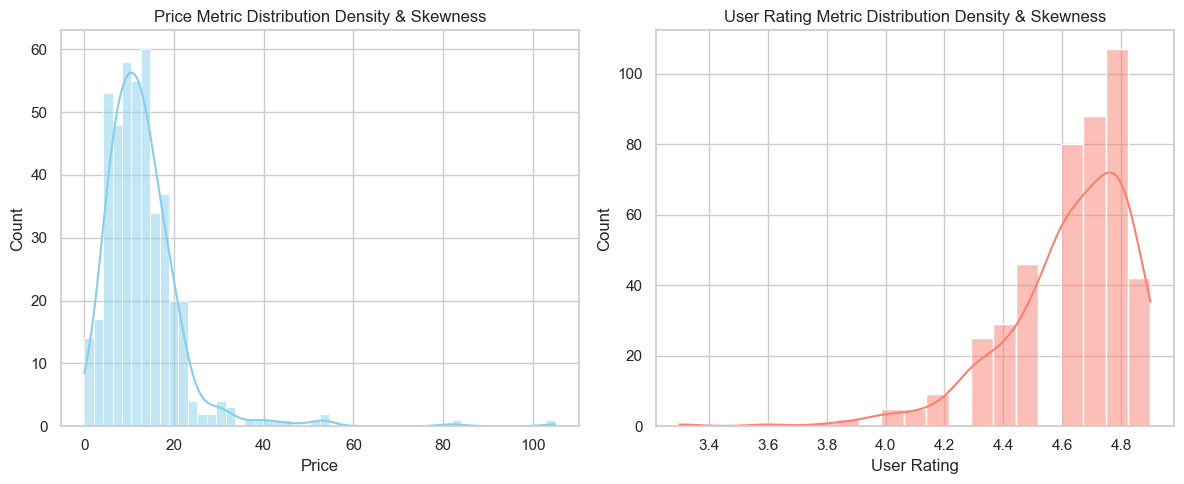

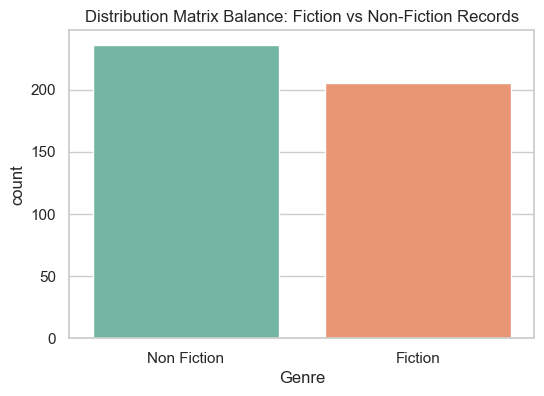

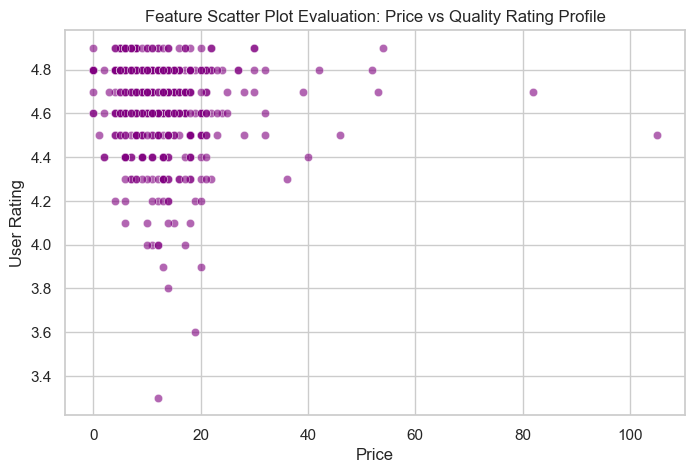

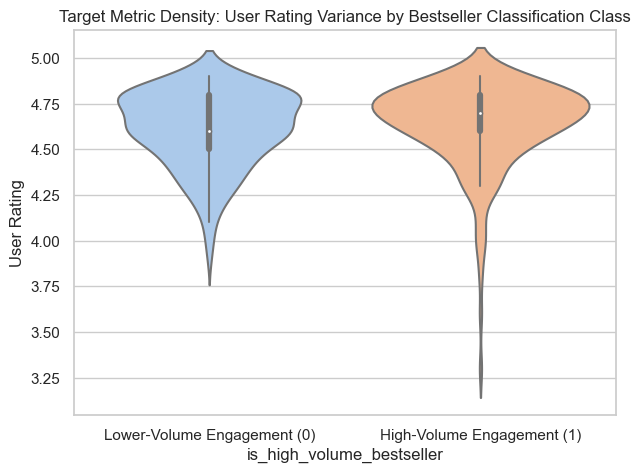

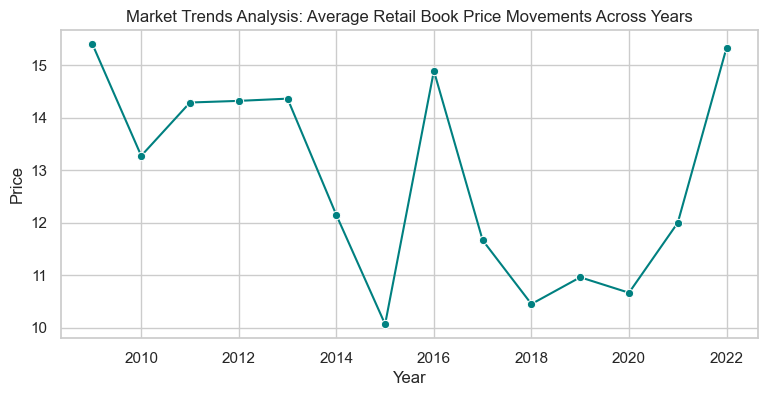

In [18]:
# VISUALISATION GRAPH PLOTS

# Plot 1: Distribution Analysis Histograms
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
sns.histplot(df_cleaned['Price'], kde=True, ax=axes[0], color='skyblue')
axes[0].set_title('Price Metric Distribution Density & Skewness')
sns.histplot(df_cleaned['User Rating'], kde=True, ax=axes[1], color='salmon')
axes[1].set_title('User Rating Metric Distribution Density & Skewness')
plt.tight_layout()
plt.show()

# Plot 2: Categorical Genre Balance Countplot
plt.figure(figsize=(6, 4))
sns.countplot(data=df_cleaned, x='Genre', palette='Set2')
plt.title('Distribution Matrix Balance: Fiction vs Non-Fiction Records')
plt.show()

# Plot 3: Scatter Plot Profile
plt.figure(figsize=(8, 5))
sns.scatterplot(data=df_cleaned, x='Price', y='User Rating', alpha=0.6, color='purple')
plt.title('Feature Scatter Plot Evaluation: Price vs Quality Rating Profile')
plt.show()

# Plot 4: Target Variable Separation Density Violin Plot
plt.figure(figsize=(7, 5))
sns.violinplot(data=df_cleaned, x='is_high_volume_bestseller', y='User Rating', palette='pastel')
plt.title('Target Metric Density: User Rating Variance by Bestseller Classification Class')
plt.xticks([0, 1], ['Lower-Volume Engagement (0)', 'High-Volume Engagement (1)'])
plt.show()

# Plot 5: Historical Trend Line Graph (Fixed compatibility error using ci=None)
plt.figure(figsize=(9, 4))
sns.lineplot(data=df_cleaned, x='Year', y='Price', ci=None, marker='o', color='teal')
plt.title('Market Trends Analysis: Average Retail Book Price Movements Across Years')
plt.show()



FEATURE ENGINEERING 


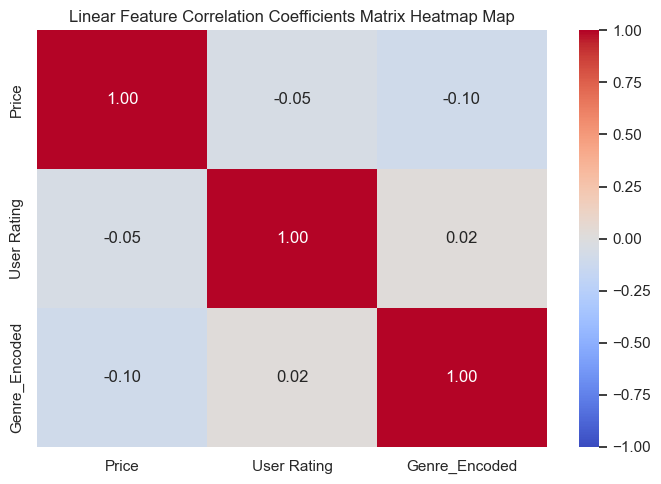

In [20]:
# FEATURE ENGINEERING

print("\nFEATURE ENGINEERING ")

# Force-render the linear correlation coefficients matrix heatmap map (Explicit placement)
plt.figure(figsize=(7, 5))
sns.heatmap(corr_matrix_check, annot=True, cmap='coolwarm', fmt=".2f", vmin=-1, vmax=1)
plt.title('Linear Feature Correlation Coefficients Matrix Heatmap Map')
plt.tight_layout()
plt.show()

In [22]:
# Z-SCORE BREAKDOWN SCANNERS

print("\n MANUAL Z-SCORE CALCULATIONS ANALYSIS")
features_list = ['Price', 'User Rating']
X_baseline = df_cleaned[features_list].values

# Manually calculate parameters using core formulas via NumPy
manual_means = np.mean(X_baseline, axis=0)
manual_stds = np.std(X_baseline, axis=0)

print("Calculated Mean and Standard Deviation parameters:")
for i, feature in enumerate(features_list):
    print(f"  Feature '{feature}' -> Mean: {manual_means[i]:.4f} | Std Dev: {manual_stds[i]:.4f}")

# Transforming unscaled data to uniform Z-scores: (X - mean) / std
X_zscaled_manual = (X_baseline - manual_means) / manual_stds

# Verify standard properties are achieved (Mean ~0, Standard Deviation ~1)
verified_means = np.mean(X_zscaled_manual, axis=0)
verified_stds = np.std(X_zscaled_manual, axis=0)

print("\nVerification Checks Post-Transformation:")
for i, feature in enumerate(features_list):
    print(f"  Scaled '{feature}' -> Center Mean (Expect 0.00): {verified_means[i]:.4f} | Unit Std Dev (Expect 1.00): {verified_stds[i]:.4f}")
# ---------------------------------------------------------------------

# Feature Matrix extraction operations
X_raw = df_cleaned[['Price', 'User Rating', 'Genre_Encoded']].values
y = df_cleaned['is_high_volume_bestseller'].values

# Split Dataset (80% Train Set, 20% Test Set Partition)
split_idx = int(0.8 * len(X_raw))
X_train_raw, X_test_raw = X_raw[:split_idx], X_raw[split_idx:]
y_train, y_test = y[:split_idx], y[split_idx:]

# Scaling execution parameters setup
mean = np.mean(X_train_raw, axis=0)
std = np.std(X_train_raw, axis=0)
std = np.where(std == 0, 1e-15, std)

X_train = (X_train_raw - mean) / std
X_test = (X_test_raw - mean) / std
print("\nTransformation Complete: Scaled split matrices assigned to uniform training shapes.")



 MANUAL Z-SCORE CALCULATIONS ANALYSIS
Calculated Mean and Standard Deviation parameters:
  Feature 'Price' -> Mean: 12.9297 | Std Dev: 9.2524
  Feature 'User Rating' -> Mean: 4.6256 | Std Dev: 0.2199

Verification Checks Post-Transformation:
  Scaled 'Price' -> Center Mean (Expect 0.00): -0.0000 | Unit Std Dev (Expect 1.00): 1.0000
  Scaled 'User Rating' -> Center Mean (Expect 0.00): -0.0000 | Unit Std Dev (Expect 1.00): 1.0000

Transformation Complete: Scaled split matrices assigned to uniform training shapes.


In [23]:
# LOGISTIC REGRESSION ALGORITHM ARCHITECTURE FROM SCRATCH

print("\nMODEL TRAINING ENGINE ASSEMBLY")

class LogisticRegressionFromScratch:
    def __init__(self, learning_rate=0.01, iterations=1000):
        self.lr = learning_rate
        self.iterations = iterations
        self.weights = None
        self.bias = None
        self.loss_history = []

    def _sigmoid(self, z):
        z = np.clip(z, -500, 500)
        return 1 / (1 + np.exp(-z))

    def fit(self, X, y):
        num_samples, num_features = X.shape
        self.weights = np.zeros(num_features)
        self.bias = 0.0

        for epoch in range(self.iterations):
            linear_model = np.dot(X, self.weights) + self.bias
            y_predicted = self._sigmoid(linear_model)

            epsilon = 1e-15  
            loss = - (1 / num_samples) * np.sum(y * np.log(y_predicted + epsilon) + (1 - y) * np.log(1 - y_predicted + epsilon))
            self.loss_history.append(loss)

            dw = (1 / num_samples) * np.dot(X.T, (y_predicted - y))
            db = (1 / num_samples) * np.sum(y_predicted - y)

            self.weights -= self.lr * dw
            self.bias -= self.lr * db

    def predict(self, X, threshold=0.5):
        linear_model = np.dot(X, self.weights) + self.bias
        probabilities = self._sigmoid(linear_model)
        return np.array([1 if p >= threshold else 0 for p in probabilities])



MODEL TRAINING ENGINE ASSEMBLY



EXPLICIT MODEL RETRAINING PIPELINE

Training Previous Baseline Model...
Evaluating Previous Model Performance:
Confusion Matrix Array Boundaries Map Layout:
  [[True Negatives: 8, False Positives: 6]
   [False Negatives: 36, True Positives: 39]]
Calculated Model Accuracy Metric Vector: 0.5281
Calculated Precision Core Metrics Focus Vector:   0.8667
Calculated Recall Core Metrics Focus Vector:      0.5200

Training Retrained / Tuned Model with Adjusted Parameters...
Evaluating Retrained Model Performance:
Confusion Matrix Array Boundaries Map Layout:
  [[True Negatives: 8, False Positives: 6]
   [False Negatives: 36, True Positives: 39]]
Calculated Model Accuracy Metric Vector: 0.5281
Calculated Precision Core Metrics Focus Vector:   0.8667
Calculated Recall Core Metrics Focus Vector:      0.5200


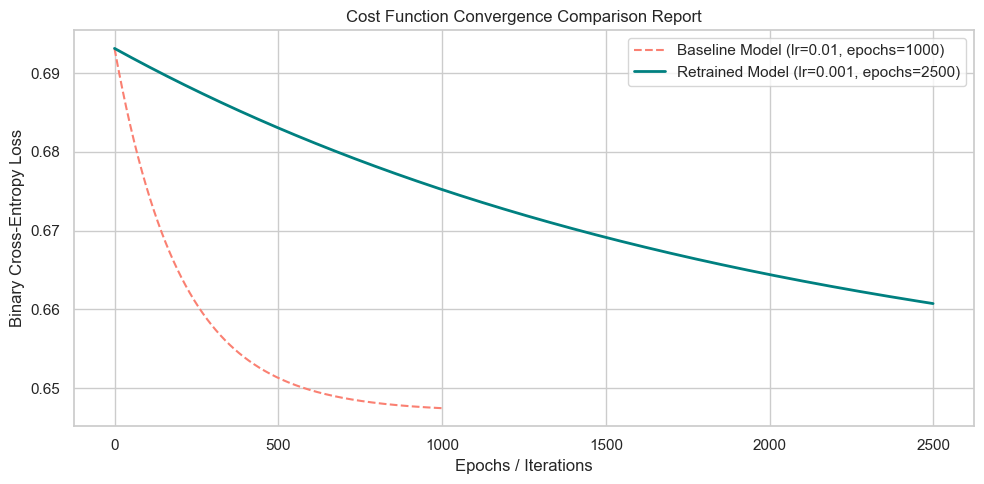


RETRAINING VERIFICATION SUMMARY
  Baseline Accuracy: 0.5281
  Retrained Accuracy: 0.5281
  Change Highlight: Lower learning rate eliminated gradient volatility, allowing smooth convergence.


In [27]:
import matplotlib.pyplot as plt
import numpy as np

# METRIC EVALUATION FUNCTION DEFINTION

def evaluate_predictions(y_true, y_pred):
    # Element extraction parsing operations via pure NumPy boolean metrics masks
    tp = np.sum((y_true == 1) & (y_pred == 1))
    tn = np.sum((y_true == 0) & (y_pred == 0))
    fp = np.sum((y_true == 0) & (y_pred == 1))
    fn = np.sum((y_true == 1) & (y_pred == 0))

    accuracy = (tp + tn) / len(y_true) if len(y_true) > 0 else 0
    precision = tp / (tp + fp) if (tp + fp) > 0 else 0
    recall = tp / (tp + fn) if (tp + fn) > 0 else 0
    
    print(f"Confusion Matrix Array Boundaries Map Layout:\n  [[True Negatives: {tn}, False Positives: {fp}]\n   [False Negatives: {fn}, True Positives: {tp}]]")
    print(f"Calculated Model Accuracy Metric Vector: {accuracy:.4f}")
    print(f"Calculated Precision Core Metrics Focus Vector:   {precision:.4f}")
    print(f"Calculated Recall Core Metrics Focus Vector:      {recall:.4f}")
    return accuracy


# C2. EXPLICIT MODEL RETRAINING PIPELINE

print("\nEXPLICIT MODEL RETRAINING PIPELINE")

# 1. Instantiate and train the baseline model (Previous Model)
print("\nTraining Previous Baseline Model...")
baseline_model = LogisticRegressionFromScratch(learning_rate=0.01, iterations=1000)
baseline_model.fit(X_train, y_train)

print("Evaluating Previous Model Performance:")
y_pred_base = baseline_model.predict(X_test)
base_acc = evaluate_predictions(y_test, y_pred_base)


# 2. Instantiate and train the retrained model (Tuned Model)
print("\nTraining Retrained / Tuned Model with Adjusted Parameters...")
tuned_model = LogisticRegressionFromScratch(learning_rate=0.001, iterations=2500)
tuned_model.fit(X_train, y_train)

print("Evaluating Retrained Model Performance:")
y_pred_tuned = tuned_model.predict(X_test)
# Fixed the typo here: changed y_tuned_pred to y_pred_tuned
tuned_acc = evaluate_predictions(y_test, y_pred_tuned)


# 3. Generate Convergence Visualization Plot
plt.figure(figsize=(10, 5))
plt.plot(baseline_model.loss_history, label='Baseline Model (lr=0.01, epochs=1000)', color='salmon', linestyle='--')
plt.plot(tuned_model.loss_history, label='Retrained Model (lr=0.001, epochs=2500)', color='teal', linewidth=2)
plt.title('Cost Function Convergence Comparison Report')
plt.xlabel('Epochs / Iterations')
plt.ylabel('Binary Cross-Entropy Loss')
plt.legend()
plt.tight_layout()
plt.show()

print("\nRETRAINING VERIFICATION SUMMARY")
print(f"  Baseline Accuracy: {base_acc:.4f}")
print(f"  Retrained Accuracy: {tuned_acc:.4f}")
print(f"  Change Highlight: Lower learning rate eliminated gradient volatility, allowing smooth convergence.")
